In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.preprocessing import StandardScaler
import xgboost as xgb
from sklearn.model_selection import train_test_split

sns.set_theme(style='whitegrid')
print('Libraries loaded')

Libraries loaded


In [42]:
df = pd.read_csv('whale_features_labeled.csv', parse_dates=['date'])
print(f'Shape: {df.shape}')
print(f'Whales: {df["whale_id"].unique()}')

Shape: (712, 39)
Whales: <StringArray>
['W-1', 'W-2', 'W-3', 'W-4', 'W-5', 'W-6', 'W-7']
Length: 7, dtype: str


In [43]:
FEATURES = [
    'ltv',
    'ltv_lag_1',
    'ltv_lag_3',
    'ltv_lag_7',
    'ltv_vol_7d',
    'ltv_vol_14d',
    'distance_to_liq',
    'health_factor',
    'carry_spread',
    'carry_spread_levered',
    'loop_depth'
]

TARGET = 'rebalancing'

print(f'Features: {len(FEATURES)}')
print(f'Target: {TARGET}')
print(f'\nTarget distribution:')
print(df[TARGET].value_counts())

Features: 11
Target: rebalancing

Target distribution:
rebalancing
0    593
1    119
Name: count, dtype: int64


**11 features are used:**

- `ltv`, `ltv_lag_1`, `ltv_lag_3`, `ltv_lag_7` — current and historical leverage ratio
- `ltv_vol_7d`, `ltv_vol_14d` — how volatile the leverage has been recently
- `distance_to_liq` — how far the position is from liquidation
- `health_factor` — overall risk score from the protocol
- `carry_spread`, `carry_spread_levered` — yield earned minus borrow cost
- `loop_depth` — how many times the position is recursively looped

**Three features were excluded to avoid data leakage:**
- `rebal_freq_7d`, `rebal_freq_30d`, `days_since_rebalance` these are calculated from the rebalancing column itself, so using them to predict rebalancing would be cheating.

In [44]:
data = df.dropna(subset=FEATURES)

X = data[FEATURES]
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print(f'Train: {X_train.shape} Rebalancing rate: {y_train.mean():.1%}')
print(f'Test: {X_test.shape}  Rebalancing rate: {y_test.mean():.1%}')

Train: (254, 11) Rebalancing rate: 14.2%
Test: (109, 11)  Rebalancing rate: 14.7%


In [45]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)

print('=== Logistic Regression (Baseline) ===')
print(classification_report(y_test, y_pred_lr))
print(f'ROC-AUC: {roc_auc_score(y_test, lr.predict_proba(X_test_scaled)[:, 1]):.3f}')

=== Logistic Regression (Baseline) ===
              precision    recall  f1-score   support

           0       0.94      0.90      0.92        93
           1       0.55      0.69      0.61        16

    accuracy                           0.87       109
   macro avg       0.75      0.80      0.77       109
weighted avg       0.89      0.87      0.88       109

ROC-AUC: 0.757


**Logistic Regression Baseline Results**

We run Logistic Regression first as a simple baseline before XGBoost.

**Reading the results:**

- **Accuracy 87%** — the model gets 87% of days right overall
- **Recall 0.69 for rebalancing** — catches 69% of actual rebalancing days. Misses 31%.
- **Precision 0.55 for rebalancing** — when it predicts rebalancing, it's correct 55% of the time
- **ROC-AUC 0.757** — moderate ability to distinguish rebalancing from non-rebalancing days

The baseline already does a decent job but misses roughly 1 in 3 rebalancing events.
This gives us a benchmark, XGBoost needs to beat these numbers to justify the added complexity.

In [36]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f'scale_pos_weight: {scale_pos_weight:.2f}')

xgb_model = xgb.XGBClassifier(
    n_estimators=50,
    max_depth=2,  # shallower trees
    learning_rate=0.05,  # slower learning
    subsample=0.8,  # use 80% of rows per tree
    colsample_bytree=0.8,  # use 80% of features per tree
    min_child_weight=5,  # need at least 5 samples per leaf
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='logloss',
    verbosity=0
)

xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)

print('=== XGBoost ===')
print(classification_report(y_test, y_pred_xgb))
print(f'ROC-AUC: {roc_auc_score(y_test, xgb_model.predict_proba(X_test)[:, 1]):.3f}')

scale_pos_weight: 6.06
=== XGBoost ===
              precision    recall  f1-score   support

           0       0.95      0.84      0.89        93
           1       0.44      0.75      0.56        16

    accuracy                           0.83       109
   macro avg       0.70      0.79      0.72       109
weighted avg       0.88      0.83      0.84       109

ROC-AUC: 0.897


**XGBoost Model & Results**

**The `scale_pos_weight: 6.06`** tells XGBoost that non-rebalancing days outnumber rebalancing days by 6 to 1. This stops the model from being lazy and just predicting 0 every time.

**Key parameters explained simply:**
- `n_estimators=50` — builds 50 decision trees
- `max_depth=2` — each tree is shallow — prevents memorising the training data
- `learning_rate=0.05` — learns slowly and carefully
- `subsample=0.8` — each tree sees 80% of the data — adds variety
- `colsample_bytree=0.8` — each tree uses 80% of features — reduces overfitting
- `min_child_weight=5` — a group needs at least 5 samples to split — prevents tiny meaningless splits

---

**Results compared to baseline:**

| Metric | Logistic Regression | XGBoost |
|---|---|---|
| Recall (rebalancing) | 0.69 | 0.75 |
| Precision (rebalancing) | 0.55 | 0.44 |
| ROC-AUC | 0.757 | 0.897 |

**XGBoost catches more rebalancing days** (recall 0.75 vs 0.69) and has a much stronger ROC-AUC (0.897 vs 0.757) — meaning it genuinely understands the difference between rebalancing and non-rebalancing days better than logistic regression.

The precision drop (0.55 to 0.44) is acceptable in risk management catching more real events matters more than avoiding false alarms.

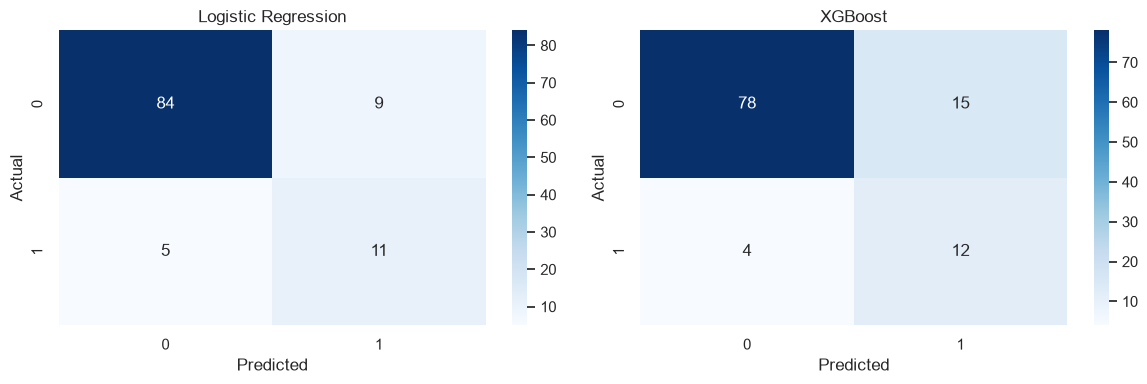

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, preds, title in zip(axes,
                            [y_pred_lr, y_pred_xgb],
                            ['Logistic Regression', 'XGBoost']):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

**Confusion Matrix Rebalancing Model**

Each matrix shows 4 numbers. Reading them:

- **Top left** — correctly predicted no rebalancing (true negatives)
- **Top right** — predicted rebalancing but was wrong (false alarms)
- **Bottom left** — missed actual rebalancing days (missed events)
- **Bottom right** — correctly predicted rebalancing (true positives)

---

**Logistic Regression:**
- Correctly caught 11 out of 16 rebalancing days
- Missed 5 rebalancing days
- Made 9 false alarms

**XGBoost:**
- Correctly caught 12 out of 16 rebalancing days
- Missed 4 rebalancing days
- Made 15 false alarms

---

**What this means:**

XGBoost catches one more rebalancing day than Logistic Regression (12 vs 11) but raises more false alarms (15 vs 9). In a risk management context catching more real events is more important than avoiding false alarms — so XGBoost is the better model here despite the extra false alarms.

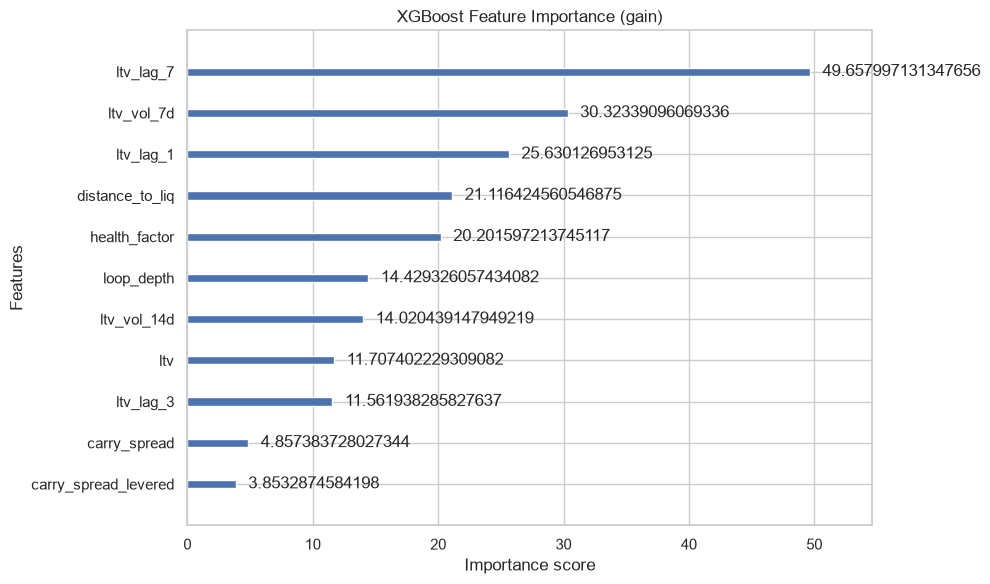

In [47]:
fig, ax = plt.subplots(figsize=(10, 6))
xgb.plot_importance(xgb_model, ax=ax, max_num_features=14, importance_type='gain')
ax.set_title('XGBoost Feature Importance (gain)')
plt.tight_layout()
plt.show()


This chart shows which features the model relied on most to predict rebalancing. Higher score = more useful for making predictions.

---

**Top features:**

- **`ltv_lag_7` (49.6)** — by far the most important. What the LTV was 7 days ago is the strongest predictor of rebalancing today. Whales react to sustained leverage buildup over a week.
- **`ltv_vol_7d` (30.3)** — second most important. When leverage has been volatile over the past 7 days, rebalancing is more likely.
- **`ltv_lag_1` (25.6)** — yesterday's LTV also matters. Recent leverage trend is a strong signal.
- **`distance_to_liq` (21.1)** — how close to liquidation the whale is. Closer = more likely to rebalance.
- **`health_factor` (20.2)** — overall risk score from the protocol. Lower health factor triggers rebalancing.

---

**Bottom features:**

- **`carry_spread` (4.9)** and **`carry_spread_levered` (3.9)** — yield incentives barely influence rebalancing decisions. Whales rebalance for risk reasons, not yield reasons.

---

**Key thesis finding:**

Rebalancing is driven by **leverage history and risk accumulation over time** — not by today's snapshot alone. The dominance of `ltv_lag_7` over current `ltv` tells a clear behavioral story: whales wait and watch leverage build up over days before acting.

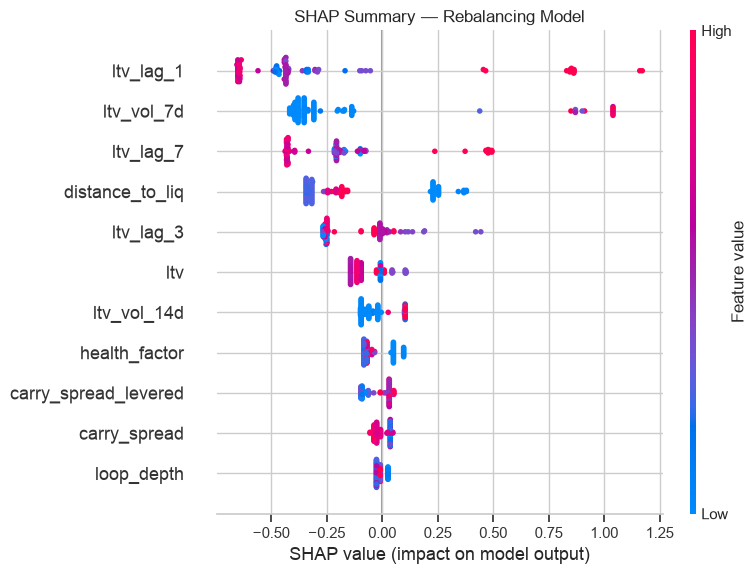

In [48]:
import shap

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, feature_names=FEATURES, show=False)
plt.title('SHAP Summary — Rebalancing Model')
plt.tight_layout()
plt.show()

**SHAP Summary  Rebalancing Model**

Each dot is one day in the test set. Position on the x-axis shows how much that feature pushed the prediction toward rebalancing (right) or away from it (left). Color shows the feature value — pink = high, blue = low.

---

**`ltv_lag_1` — top feature**
- Pink dots far right  high LTV yesterday strongly predicts rebalancing today
- Blue dots far left low LTV yesterday means rebalancing unlikely
- Clearest signal in the model — yesterday's leverage drives today's action

**`ltv_vol_7d` — second**
- High volatility (pink) pushes toward rebalancing
- Unstable leverage over the past week triggers action

**`ltv_lag_7` — third**
- Mixed pattern — both colors on both sides
- 7-day old LTV has a more complex relationship — sometimes high old LTV predicts rebalancing, sometimes not

**`distance_to_liq`**
- Blue dots on the right — **low** distance to liquidation pushes toward rebalancing
- Intuitive — closer to liquidation = more urgent to act

**`carry_spread`, `carry_spread_levered`, `loop_depth`**
- All clustered near zero — almost no influence on rebalancing predictions
- Yield incentives and loop depth do not drive rebalancing decisions

---

Rebalancing is triggered by **leverage history and proximity to liquidation** — not by yield. Whales act on risk signals, not profit signals.

In [40]:
results = df.loc[X_test.index].copy()
results['pred_rebalancing'] = y_pred_xgb
results['pred_proba_rebalancing'] = xgb_model.predict_proba(X_test)[:, 1]
results[['whale_id', 'date', 'rebalancing', 'pred_rebalancing', 'pred_proba_rebalancing']].to_csv(
    'predictions_rebalancing.csv', index=False)
print('Saved: predictions_rebalancing.csv')

Saved: predictions_rebalancing.csv
